# Calibrated Equalized Odds on credit default data

Runs the full pipeline on all three datasets and produces every table and figure used in the README.

**Method:** Calibrated Equalized Odds post-processing (Pleiss et al., *On Fairness and Calibration*, NeurIPS 2017), via AIF360's `CalibratedEqOddsPostprocessing`.
**Datasets:** German Credit (protected: age, older than 25 = privileged), Taiwan credit card default (sex, male = privileged), Home Credit Default Risk (sex, male = privileged). Label 1 = repays (favourable), so a positive prediction is an approval.

**Per dataset and seed:** fairness of the original labels → stratified 60/20/20 split on label × group → train the base model (missing values imputed inside the model, on the training split only) → choose the cutoff on validation (max TPR − FPR) → fit the post-processor on validation, apply it to test → evaluate baseline and mitigated predictions on test.

## Settings

In [1]:
DATASETS = ["german", "taiwan", "homecredit"]
MODEL = "lr"            # "lr" = logistic regression, "gbm" = gradient boosting with isotonic calibration
CONSTRAINT = "fnr"      # generalised error rate to equalise: "fnr", "fpr" or "weighted"
SEEDS = 5               # number of random stratified splits
FIG_DIR = "../figures"  # tables and plots are saved here

In [2]:
import sys, logging, warnings
from pathlib import Path
sys.path.insert(0, "../src")
logging.getLogger().setLevel(logging.ERROR)   # hide AIF360's optional-dependency notices
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from fair_credit.data import load
from fair_credit.metrics import label_metrics
from fair_credit.pipeline import run_once
from fair_credit.plots import reliability

Path(FIG_DIR).mkdir(exist_ok=True)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## 1. Run the pipeline

Home Credit takes a few minutes; German and Taiwan are quick.

In [3]:
label_rows, run_rows, datasets = [], [], {}
for name in DATASETS:
    ds = load(name)
    datasets[name] = ds
    print(f"{name}: {len(ds.y):,} rows, {ds.X.shape[1]} features, protected = {ds.protected} (privileged: {ds.privileged_desc})")
    label_rows.append({"dataset": name, **label_metrics(ds.X.to_numpy(), ds.y, ds.s)})
    for seed in range(SEEDS):
        base, mitig, curves = run_once(ds, MODEL, CONSTRAINT, seed)
        run_rows += [{"dataset": name, "seed": seed, "stage": "baseline", **base},
                     {"dataset": name, "seed": seed, "stage": "ceo", **mitig}]
        if seed == 0:
            reliability(curves, f"{name}, {MODEL}, constraint = {CONSTRAINT}",
                        Path(FIG_DIR) / f"{name}_{MODEL}_{CONSTRAINT}_reliability.png")

runs = pd.DataFrame(run_rows)
runs.to_csv(Path(FIG_DIR) / f"runs_{MODEL}_{CONSTRAINT}.csv", index=False)

german: 1,000 rows, 60 features, protected = age (privileged: age > 25)
taiwan: 30,000 rows, 31 features, protected = sex (privileged: male)
homecredit: 307,507 rows, 122 features, protected = sex (privileged: male)


## 2. Fairness of the original labels

DP_Diff = P(y=1 | unprivileged) − P(y=1 | privileged), fair at 0. DIR = their ratio, fair at 1 (0.8 to 1.25 is the usual bound). Consistency compares each person's label with their 5 nearest neighbours on standardised features.

`consistency (full data)` uses all rows. Consistency of predictions can only be measured on the test set, where neighbourhoods are sparser, so `consistency (test rows)` gives the label consistency on exactly those rows: that is the like-for-like reference for Table 2.

In [4]:
labels = pd.DataFrame(label_rows).set_index("dataset").rename(columns={"consistency": "consistency (full data)"})
labels["consistency (test rows)"] = runs[runs.stage == "baseline"].groupby("dataset")["consistency_labels_test"].mean()
labels.to_csv(Path(FIG_DIR) / "original_labels.csv")
labels

,dp_diff,dir,consistency (full data),consistency (test rows)
dataset,,,,
german,-0.149,0.795,0.666,0.657
taiwan,0.034,1.045,0.726,0.727
homecredit,0.031,1.035,0.857,0.860


## 3. Before and after mitigation (test set)

Mean over the seeds, standard deviation in brackets. `n` shows on how many seeds a mean is based (DIR and the default rate among approved are undefined when a group has no approvals). Means hide a lot when the method behaves differently per seed, so check Section 5 before reading these as averages.

In [5]:
METRICS = ["dp_diff", "dir", "consistency", "balanced_accuracy", "auc", "accuracy",
           "gfnr_gap", "gfpr_gap", "ece_priv", "ece_unpriv",
           "approval_priv", "approval_unpriv", "default_among_approved_priv", "default_among_approved_unpriv",
           "threshold"]

def fmt(x):
    x = x.dropna()
    s = f"{x.mean():.3f} ({x.std():.3f})"
    return s if len(x) == SEEDS else s + f" n={len(x)}"

table = (runs.melt(id_vars=["dataset", "seed", "stage"], value_vars=METRICS, var_name="metric")
             .groupby(["metric", "dataset", "stage"], sort=False)["value"].apply(fmt)
             .unstack(["dataset", "stage"]).reindex(METRICS))
table.to_csv(Path(FIG_DIR) / f"before_after_{MODEL}_{CONSTRAINT}.csv")
table

dataset                                german                             taiwan                      homecredit                
stage                                baseline                ceo        baseline             ceo        baseline             ceo
metric                                                                                                                          
dp_diff                        -0.163 (0.075)     -0.137 (0.528)   0.031 (0.010)   0.155 (0.046)   0.091 (0.005)   0.221 (0.178)
dir                             0.738 (0.127)  0.482 (0.080) n=3   1.042 (0.015)   1.209 (0.065)   1.155 (0.014)   1.377 (0.307)
consistency                     0.700 (0.023)      0.857 (0.025)   0.939 (0.008)   0.876 (0.018)   0.700 (0.006)   0.751 (0.069)
balanced_accuracy               0.696 (0.019)      0.541 (0.033)   0.687 (0.005)   0.630 (0.022)   0.677 (0.002)   0.642 (0.046)
auc                             0.771 (0.015)      0.573 (0.022)   0.728 (0.005)   0.672 (0.023)   0.739 (0.002)   0.693 (0.063)
accuracy                        0.703 (0.028)      0.564 (0.207)   0.776 (0.012)   0.778 (0.009)   0.680 (0.015)   0.741 (0.080)
gfnr_gap                        0.101 (0.067)      0.044 (0.057)  -0.013 (0.003)  -0.000 (0.006)  -0.013 (0.000)  -0.014 (0.001)
gfpr_gap                       -0.006 (0.019)     -0.228 (0.045)   0.017 (0.009)   0.086 (0.024)   0.019 (0.005)   0.046 (0.037)
ece_priv                        0.087 (0.015)      0.000 (0.000)   0.040 (0.006)   0.040 (0.006)   0.012 (0.001)   0.012 (0.001)
ece_unpriv                      0.207 (0.024)      0.207 (0.024)   0.053 (0.007)   0.024 (0.011)   0.005 (0.000)   0.003 (0.003)
approval_priv                   0.626 (0.040)      0.600 (0.548)   0.744 (0.028)   0.744 (0.028)   0.591 (0.020)   0.591 (0.020)
approval_unpriv                 0.463 (0.090)      0.463 (0.090)   0.775 (0.027)   0.899 (0.040)   0.683 (0.016)   0.813 (0.172)
default_among_approved_priv     0.144 (0.012)  0.272 (0.000) n=3   0.148 (0.009)   0.148 (0.009)   0.048 (0.003)   0.048 (0.003)
default_among_approved_unpriv   0.260 (0.027)      0.260 (0.027)   0.129 (0.005)   0.178 (0.015)   0.037 (0.001)   0.050 (0.018)
threshold                       0.695 (0.058)      0.695 (0.058)   0.736 (0.013)   0.736 (0.013)   0.920 (0.004)   0.920 (0.004)

## 4. Did the method reach its own target?

The method equalises a *generalised* error rate, computed from scores. For `fnr` that is the mean of 1 − score over people who repaid. The targeted gap should shrink towards 0; the other gap is free to grow.

In [6]:
target, other = ("gfnr_gap", "gfpr_gap") if CONSTRAINT == "fnr" else ("gfpr_gap", "gfnr_gap")
gaps = runs.groupby(["dataset", "stage"], sort=False)[[target, other]].mean().unstack("stage").round(4)
gaps

gfnr_gap            gfpr_gap       
stage      baseline        ceo baseline    ceo
dataset                                       
german        0.101  4.420e-02   -0.006 -0.228
taiwan       -0.013 -3.000e-04    0.017  0.086
homecredit   -0.013 -1.370e-02    0.019  0.046

## 5. Per seed: feasibility, mixing rate and outcome

Computed on the validation set, where the post-processor is fitted. The degraded group is moved towards its constant base-rate classifier, the worst *calibrated* classifier it can have.

- `headroom` = trivial cost − current cost of the degraded group. A calibrated model always has headroom > 0. Headroom ≤ 0 means the model is not calibrated for that group on this measure, and the method's assumption breaks.
- `feasible`: the other group's cost is at most the degraded group's trivial cost (Section 4 of the paper).
- `mix rate`: share of the degraded group whose score is replaced by the base rate. AIF360 does not clip it: above 1 means everyone is replaced, below 0 means nobody is.

In [7]:
ceo = runs[runs.stage == "ceo"].copy()
ceo["degraded group"] = np.where(ceo["val_degraded_is_priv"] == 1, "privileged", "unprivileged")
ceo["mix rate"] = np.where(ceo["val_degraded_is_priv"] == 1, ceo["mix_rate_priv"], ceo["mix_rate_unpriv"])
ceo["what happened"] = np.select([ceo["mix rate"] <= 0, ceo["mix rate"] >= 1],
                                 ["nobody replaced", "everyone replaced"], "part replaced")
per_seed = ceo.set_index(["dataset", "seed"])[[
    "degraded group", "val_cost_degraded", "val_trivial_cost_degraded", "val_headroom",
    "val_cost_other", "val_feasible", "mix rate", "what happened",
    "dp_diff", "dir", "approval_priv", "approval_unpriv", "threshold"]].rename(columns={
    "val_cost_degraded": "cost", "val_trivial_cost_degraded": "trivial cost", "val_headroom": "headroom",
    "val_cost_other": "other group cost", "val_feasible": "feasible"})
per_seed["feasible"] = per_seed["feasible"].map({1.0: "yes", 0.0: "no"})
per_seed.to_csv(Path(FIG_DIR) / f"per_seed_{MODEL}_{CONSTRAINT}.csv")
per_seed.round(4)

degraded group   cost  trivial cost   headroom  other group cost feasible  mix rate      what happened  dp_diff    dir  approval_priv  approval_unpriv  threshold
dataset    seed                                                                                                                                                                  
german     0        privileged  0.241         0.272  3.080e-02             0.306       no     2.126  everyone replaced    0.526    NaN          0.000            0.526      0.752
           1        privileged  0.224         0.272  4.790e-02             0.350       no     2.633  everyone replaced   -0.605  0.395          1.000            0.395      0.709
           2        privileged  0.209         0.272  6.280e-02             0.342       no     2.123  everyone replaced   -0.500  0.500          1.000            0.500      0.682
           3        privileged  0.223         0.272  4.860e-02             0.362       no     2.866  everyone replaced   -0.447  0.553          1.000            0.553      0.602
           4        privileged  0.235         0.272  3.700e-02             0.290       no     1.502  everyone replaced    0.342    NaN          0.000            0.342      0.729
taiwan     0      unprivileged  0.187         0.208  2.040e-02             0.196      yes     0.429      part replaced    0.151  1.209          0.724            0.876      0.739
           1      unprivileged  0.180         0.208  2.750e-02             0.192      yes     0.420      part replaced    0.103  1.130          0.793            0.897      0.715
           2      unprivileged  0.183         0.208  2.460e-02             0.199      yes     0.668      part replaced    0.193  1.264          0.729            0.921      0.749
           3      unprivileged  0.183         0.208  2.470e-02             0.202      yes     0.779      part replaced    0.208  1.280          0.743            0.952      0.736
           4      unprivileged  0.184         0.208  2.380e-02             0.192      yes     0.360      part replaced    0.117  1.160          0.731            0.848      0.740
homecredit 0      unprivileged  0.070         0.070 -4.000e-04             0.083       no   -31.505    nobody replaced    0.091  1.150          0.609            0.701      0.916
           1      unprivileged  0.071         0.070 -7.000e-04             0.082       no   -16.637    nobody replaced    0.083  1.135          0.615            0.698      0.916
           2      unprivileged  0.070         0.070  2.000e-04             0.084       no    80.305  everyone replaced    0.416  1.712          0.584            1.000      0.921
           3      unprivileged  0.070         0.070  1.000e-04             0.084       no   180.941  everyone replaced    0.417  1.714          0.583            1.000      0.921
           4      unprivileged  0.071         0.070 -8.000e-04             0.085       no   -18.232    nobody replaced    0.099  1.174          0.566            0.664      0.924

Summary per dataset: how often each outcome occurred, and the spread of DP_Diff after mitigation.

In [8]:
summary = pd.DataFrame({
    "feasible seeds": per_seed["feasible"].eq("yes").groupby("dataset").sum(),
    "min headroom": per_seed["headroom"].groupby("dataset").min(),
    "nobody replaced": per_seed["what happened"].eq("nobody replaced").groupby("dataset").sum(),
    "part replaced": per_seed["what happened"].eq("part replaced").groupby("dataset").sum(),
    "everyone replaced": per_seed["what happened"].eq("everyone replaced").groupby("dataset").sum(),
    "DP_Diff after, min": per_seed["dp_diff"].groupby("dataset").min(),
    "DP_Diff after, max": per_seed["dp_diff"].groupby("dataset").max(),
}).reindex(DATASETS)
summary.to_csv(Path(FIG_DIR) / f"outcome_summary_{MODEL}_{CONSTRAINT}.csv")
summary.round(4)

,feasible seeds,min headroom,nobody replaced,part replaced,everyone replaced,"DP_Diff after, min","DP_Diff after, max"
dataset,,,,,,,
german,0,3.080e-02,0,0,5,-0.605,0.526
taiwan,5,2.040e-02,0,5,0,0.103,0.208
homecredit,0,-8.000e-04,3,0,2,0.083,0.417


## 6. Calibration per group, before and after (seed 0)

Points on the diagonal mean the scores are calibrated for that group. A group whose scores were replaced by its base rate collapses to a few points. Section 3 also reports the expected calibration error (ECE) per group.

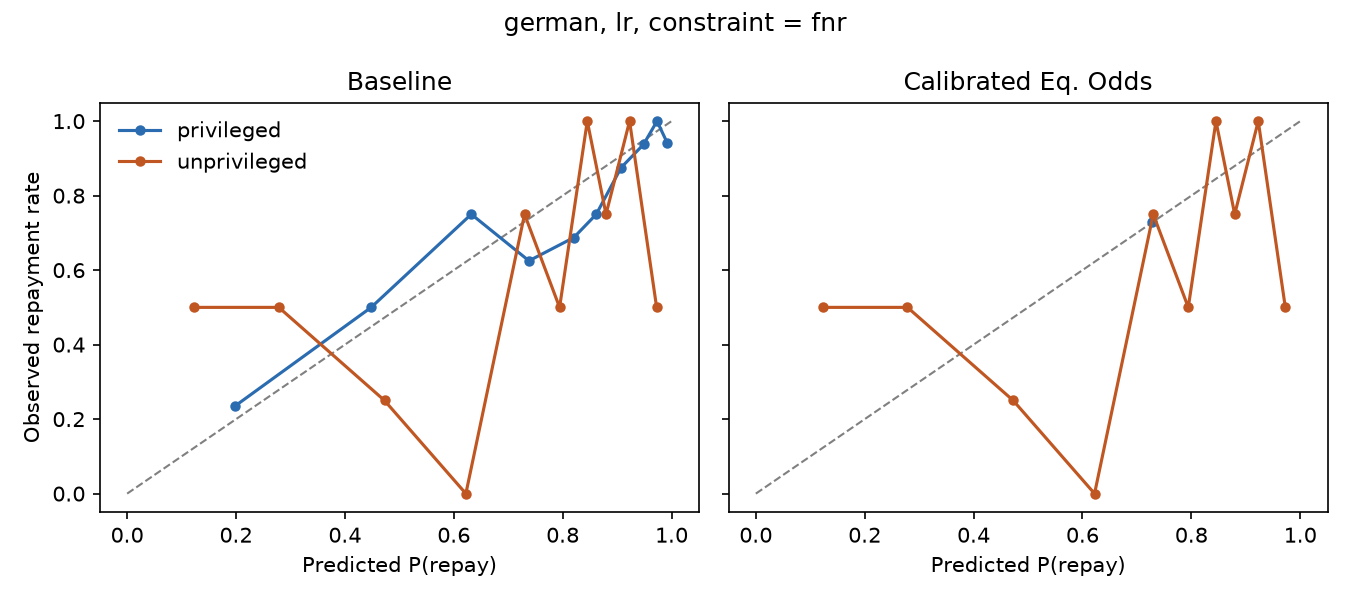

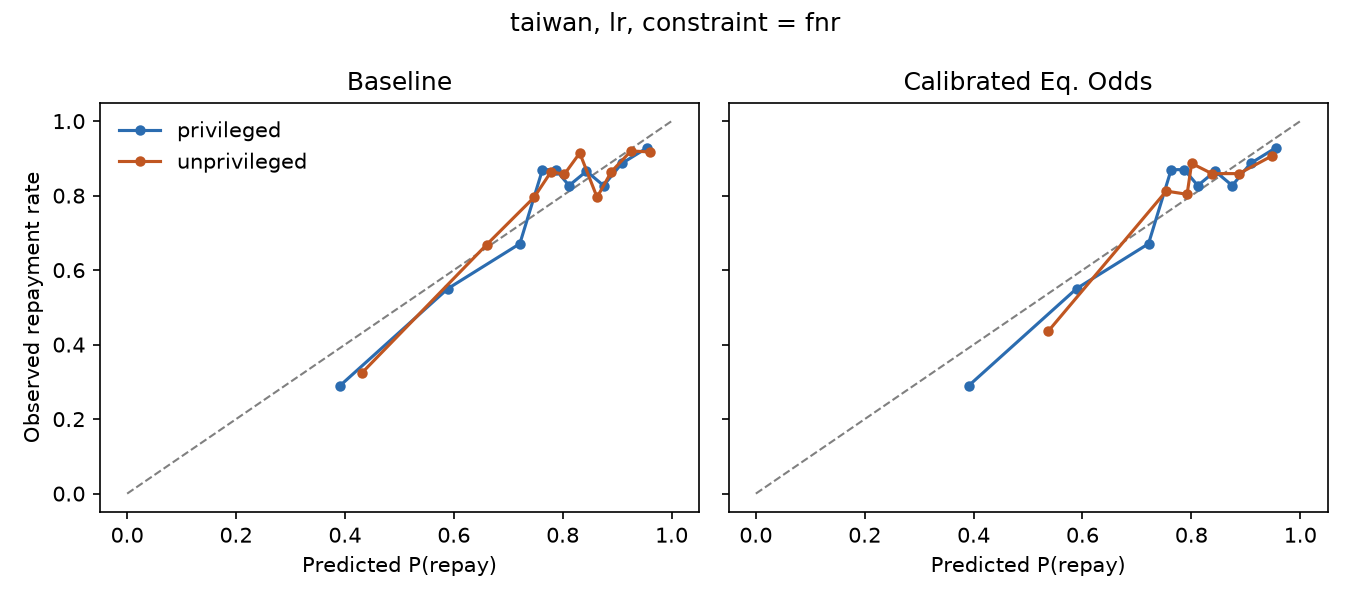

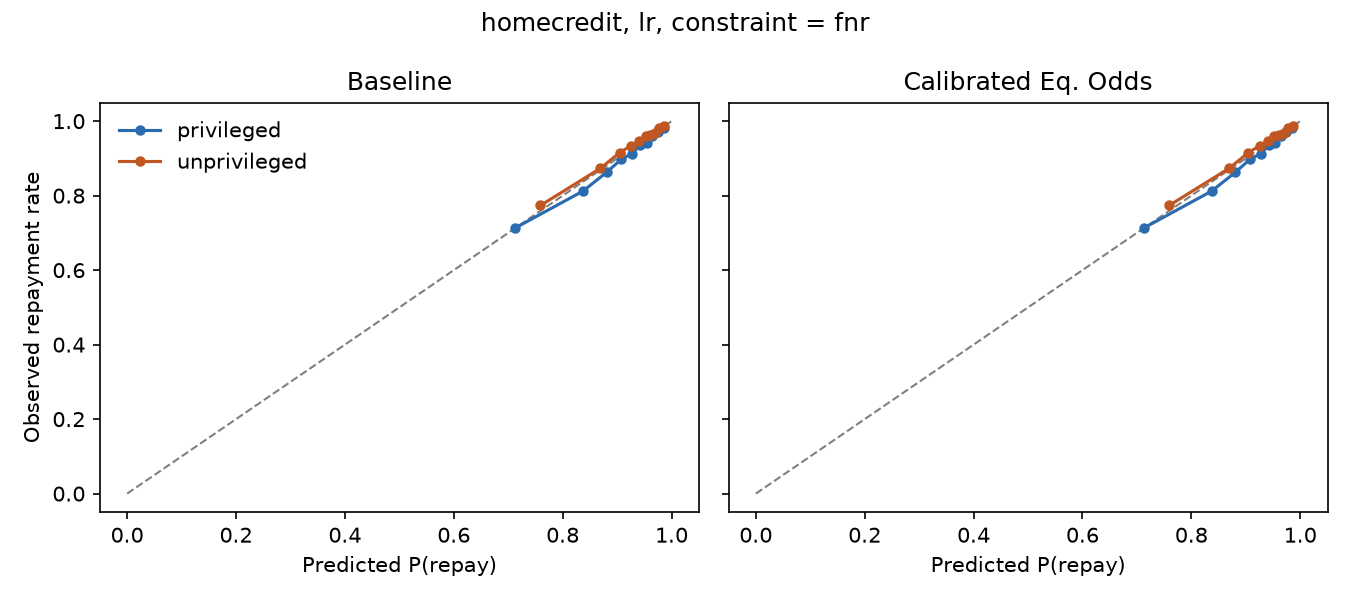

In [9]:
for name in DATASETS:
    display(Image(filename=str(Path(FIG_DIR) / f"{name}_{MODEL}_{CONSTRAINT}_reliability.png")))